In [1]:
import numpy as np 
import pandas as pd
from pandas import read_csv
from matplotlib import pyplot
%matplotlib inline
import seaborn as sn
import matplotlib.pyplot as plt




In [2]:
data = read_csv('T:/_Data analysis/High stake punter/sabaclub.csv')

#check type, statistic
data.head()

data.info()

data['AVG_StakeORG']=data['MemberTurnoverORG']/data['betcount']

data.describe()


#check null
data.isnull().sum()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36506 entries, 0 to 36505
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   custid             36506 non-null  int64  
 1   username           36506 non-null  object 
 2   betcount           36506 non-null  int64  
 3   MemberTurnover     36506 non-null  float64
 4   MemberTurnoverORG  36506 non-null  int64  
 5   MemberWinloss      36506 non-null  float64
 6   MemberWinlossORG   36506 non-null  float64
 7   AVG_Stake          36506 non-null  float64
 8   HouseTO            36506 non-null  float64
 9   HouseTOORG         36506 non-null  float64
 10  HouseIncome        36506 non-null  float64
 11  HouseIncomeORG     36506 non-null  float64
dtypes: float64(8), int64(3), object(1)
memory usage: 3.3+ MB


custid               0
username             0
betcount             0
MemberTurnover       0
MemberTurnoverORG    0
MemberWinloss        0
MemberWinlossORG     0
AVG_Stake            0
HouseTO              0
HouseTOORG           0
HouseIncome          0
HouseIncomeORG       0
AVG_StakeORG         0
dtype: int64

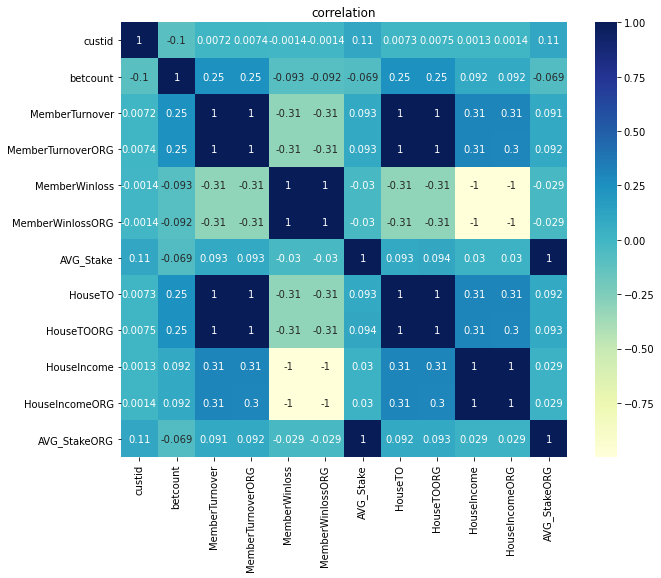

In [11]:

#correlation
plt.figure(figsize=(10, 8))
plt.title('correlation')

cor=data.corr()
sn.heatmap(cor,   cmap="YlGnBu",annot=True)
plt.show()

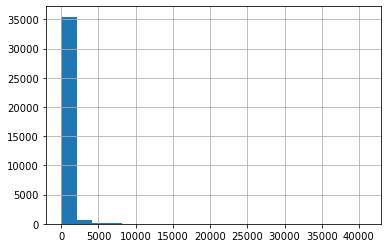

In [64]:

#
data.betcount.hist(bins=20)

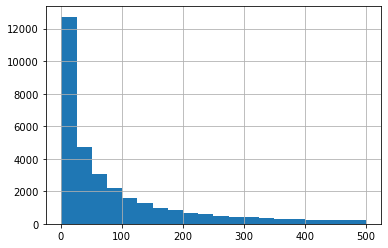

In [67]:

data[data['betcount']<=500].betcount.hist(bins=20)

In [8]:

filterBetcount= data[data['betcount']>=0]
 


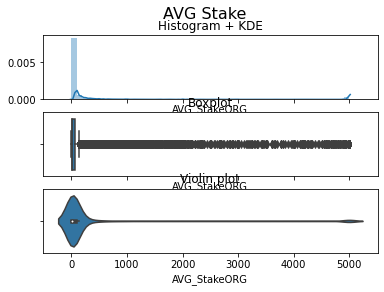

In [9]:
#filterBetcount1= data[data['betcount']<10]
#t=filterBetcount1.describe()

def plot_comparison(x, title):
    fig, ax = plt.subplots(3, 1, sharex=True)
    sn.distplot(x, ax=ax[0])
    ax[0].set_title('Histogram + KDE')
    sn.boxplot(x, ax=ax[1])
    ax[1].set_title('Boxplot')
    sn.violinplot(x, ax=ax[2])
    ax[2].set_title('Violin plot')
    fig.suptitle(title, fontsize=16)
    plt.show()
 

plot_comparison(filterBetcount['AVG_StakeORG'], 'AVG Stake')

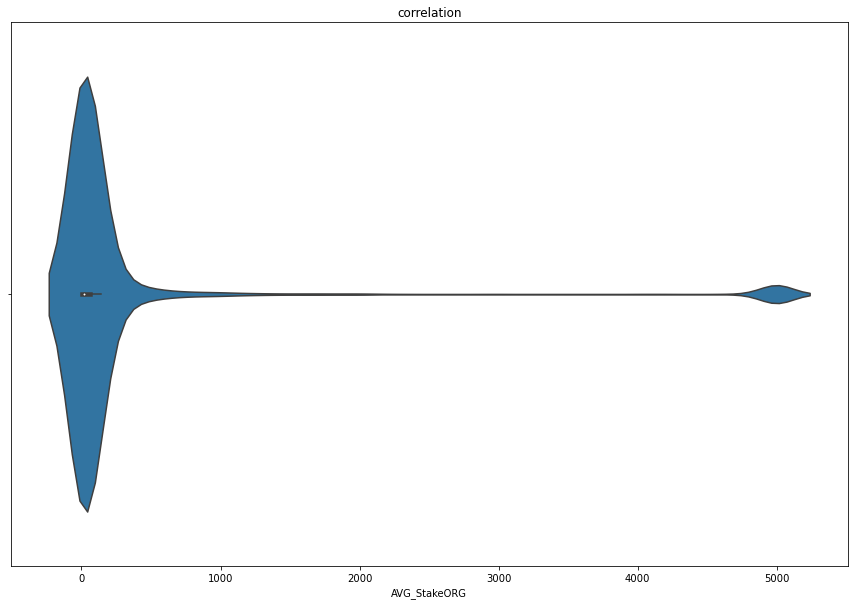

In [11]:
plt.figure(figsize=(15, 10))
plt.title('correlation')
sn.violinplot(filterBetcount['AVG_StakeORG'] )

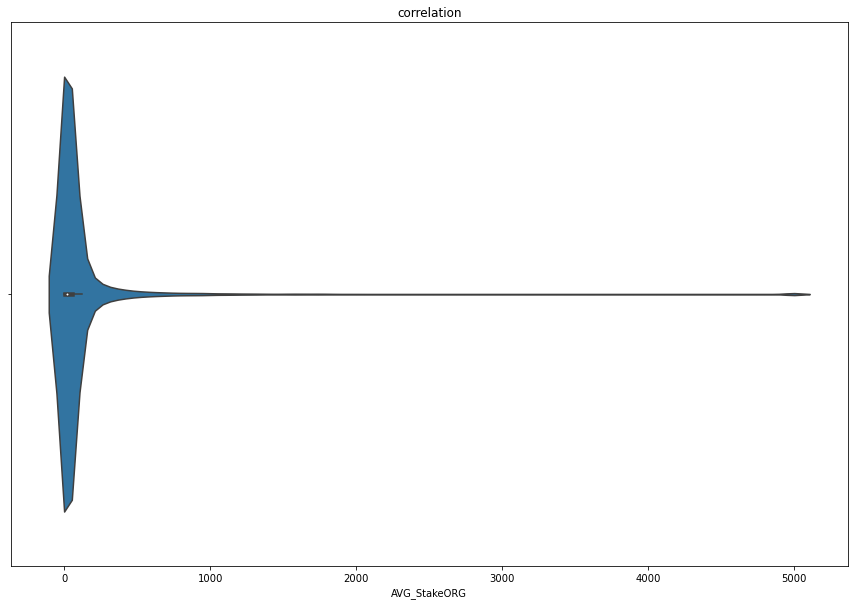

In [7]:

filterBetcount= data[data['betcount']>5]
plt.figure(figsize=(15, 10))
plt.title('correlation')
sn.violinplot(filterBetcount['AVG_StakeORG'] )

In [5]:

#outlier

# Q1 = filterBetcount['AVG_StakeORG'].quantile(0.25)
# Q3 = filterBetcount['AVG_StakeORG'].quantile(0.75)
# IQR = Q3 - Q1
# print(IQR)
# print(Q1 - 1.5 * IQR)
# print(Q3 + 1.5 * IQR)


# Q1 = filterBetcount['AVG_Stake'].quantile(0.25)
# Q3 = filterBetcount['AVG_Stake'].quantile(0.75)
# IQR = Q3 - Q1
# print(IQR)
# print(Q1 - 1.5 * IQR)
# print(Q3 + 1.5 * IQR)

#95th percentile of AVGStake is considered outlier


AVGStakeOutlier95ORG = data['AVG_StakeORG'].quantile(0.95)
print (AVGStakeOutlier95ORG)

1153.9873222016079


[1153.9873222016079, 544.6058917197452, 446.3703881048387, 424.2652597402596, 392.95587665406384, 381.01569306930674, 369.7467479674795, 363.6320454545452, 357.3975279106859, 354.93975903614455]


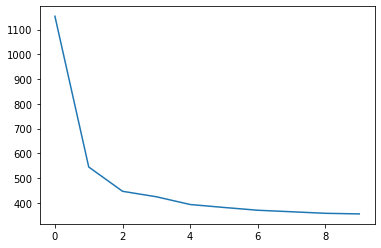

In [6]:

outlierbyFilteredBetcount=[]
for x in range(10):
  #print(x) 
  filterBetcount= data[data['betcount']>x]
  AVGStakeOutlier95 = filterBetcount['AVG_StakeORG'].quantile(0.95)
  outlierbyFilteredBetcount.append(AVGStakeOutlier95)
 
pyplot.plot(outlierbyFilteredBetcount)
print(outlierbyFilteredBetcount)

In [3]:
 
# outlier --> high stake punter
filterHighStake= data[(data['AVG_StakeORG']>=370) & (data['betcount']>5)]
filterHighStake

,custid,username,betcount,MemberTurnover,MemberTurnoverORG,MemberWinloss,MemberWinlossORG,AVG_Stake,HouseTO,HouseTOORG,HouseIncome,HouseIncomeORG,AVG_StakeORG
228,35377420,QZ3H0412009,65,1.111336e+05,29960,-13044.4760,-3516.60,1709.7480,16670.0436,4494.00,1956.6714,527.490,460.923077
351,35670751,ET1E201004,6,1.084050e+04,3000,-216.8100,-60.00,1806.7500,1626.0750,450.00,32.5215,9.000,500.000000
377,40089663,SJK6D1010001,1972,3.830575e+06,1032667,-84113.3158,-22675.72,1942.4822,574586.2455,154900.05,12616.9975,3401.358,523.664807
383,41209514,TV743B01000,34,5.916493e+04,15950,2997.1952,808.00,1740.1450,8874.7395,2392.50,-449.5793,-121.200,469.117647
443,41682507,TV743B03003,37,7.431305e+04,20300,-9528.2371,-2581.60,2008.4608,11146.9575,3045.00,1429.2356,387.240,548.648649
...,...,...,...,...,...,...,...,...,...,...,...,...,...
36437,47966347,SJKBB800Q005,9,1.517670e+05,42000,26197.8750,7250.00,16863.0000,22765.0500,6300.00,-3929.6813,-1087.500,4666.666667
36448,47980238,8QJ5000100X,20,5.528655e+04,15300,-17749.5120,-4912.00,2764.3275,8292.9825,2295.00,2662.4268,736.800,765.000000
36450,47981289,BV8661C000,6,1.084050e+05,30000,33244.2000,9200.00,18067.5000,16260.7500,4500.00,-4986.6300,-1380.000,5000.000000
36460,47989230,KG18090D00C,427,1.103418e+06,305360,-90130.8078,-24942.80,2584.1179,165512.7541,45804.00,13519.6212,3741.420,715.128806


In [13]:
punterdata = read_csv('T:/_Data analysis/High stake punter/high stake punter model- Sabaclub.csv')

#check type, statistic
punterdata.head()

punterdata.info()

punterdata['Frequency']=punterdata['SabaClub_ActiveDays']/(punterdata['NumberOfDayFromFirstActive']+1)


punterdata.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1598 entries, 0 to 1597
Data columns (total 27 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   custid                      1598 non-null   int64  
 1   username                    1598 non-null   object 
 2   Closed                      1598 non-null   bool   
 3   betcount                    1598 non-null   int64  
 4   HouseTO                     1598 non-null   float64
 5   HouseTOORG                  1598 non-null   float64
 6   FirstActiveDays             1598 non-null   object 
 7   LastActiveDays              1598 non-null   object 
 8   ActiveDays                  1598 non-null   int64  
 9   AVGStakeORG                 1598 non-null   float64
 10  SportbookHouseTO            1598 non-null   float64
 11  SportbookHouseTOORG         1598 non-null   float64
 12  SportbookAVGStakeORG        1598 non-null   float64
 13  OtherNonsportTO             1598 

,custid,betcount,HouseTO,HouseTOORG,ActiveDays,AVGStakeORG,SportbookHouseTO,SportbookHouseTOORG,SportbookAVGStakeORG,OtherNonsportTO,...,SabaClubHouseTO,SabaClubTOORG,SabaClubAVGStakeORG,SabaClub_ActiveDays,SabaClubHouseTO%,SportbookHouseTO%,OtherNonsportTO%,NumberOfDayFromFirstActive,NumberOfDayInactive,Frequency
count,1.598000e+03,1598.000000,1.598000e+03,1.598000e+03,1598.000000,1598.000000,1.598000e+03,1.598000e+03,1598.000000,1598.000000,...,1.598000e+03,1.598000e+03,1598.000000,1598.000000,1598.000000,1598.000000,1598.000000,1598.000000,1598.000000,1598.000000
mean,4.712956e+07,366.821026,1.614059e+05,4.391429e+04,5.521902,994.242770,4.036832e+04,1.101247e+04,422.600307,3796.377572,...,1.172412e+05,3.187287e+04,1336.664690,3.123905,0.812319,0.169105,0.018524,31.047559,26.610138,0.155621
std,1.159720e+06,842.580596,3.807751e+05,1.032783e+05,8.287898,943.071343,2.166278e+05,5.884896e+04,970.548709,29979.795517,...,2.986901e+05,8.095784e+04,1360.760720,4.361230,0.305067,0.290939,0.101582,19.211547,18.595589,0.199927
min,3.361206e+07,6.000000,1.271397e+03,3.427500e+02,1.000000,14.469000,0.000000e+00,0.000000e+00,0.000000,0.000000,...,1.271397e+03,3.427500e+02,370.000000,1.000000,0.001100,0.000000,0.000000,0.000000,0.000000,0.016129
25%,4.699638e+07,41.000000,1.714443e+04,4.645200e+03,1.000000,462.597950,0.000000e+00,0.000000e+00,0.000000,0.000000,...,1.278420e+04,3.505875e+03,499.053550,1.000000,0.730150,0.000000,0.000000,14.000000,9.000000,0.033333
50%,4.736896e+07,131.000000,4.680215e+04,1.283375e+04,2.000000,694.216400,0.000000e+00,0.000000e+00,0.000000,0.000000,...,2.769477e+04,7.560900e+03,757.950300,2.000000,1.000000,0.000000,0.000000,31.000000,25.000000,0.071429
75%,4.771733e+07,384.250000,1.560895e+05,4.298549e+04,6.000000,1101.520575,1.340385e+04,3.686783e+03,515.400575,0.000000,...,9.694591e+04,2.646975e+04,1437.611425,3.000000,1.000000,0.211450,0.000000,48.000000,42.000000,0.200000
max,4.802620e+07,20315.000000,5.125645e+06,1.384623e+06,57.000000,6935.022400,4.779555e+06,1.291322e+06,10000.000000,591180.060900,...,5.117288e+06,1.379546e+06,5000.000000,39.000000,1.000000,0.998800,0.972800,61.000000,61.000000,1.000000


In [14]:
#from pandas_profiling import ProfileReport
#prof = ProfileReport(punterdata)
#prof.to_file(output_file='output.html')

In [15]:
#EDA
import dtale
dtale.show(punterdata, ignore_duplicate=True)


In [17]:

#clean some new member, just place some day on sabaclub, not enough data
filterData=punterdata[punterdata['NumberOfDayFromFirstActive']>6] 

filterData.info()
filterData

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1379 entries, 0 to 1408
Data columns (total 28 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   custid                      1379 non-null   int64  
 1   username                    1379 non-null   object 
 2   Closed                      1379 non-null   bool   
 3   betcount                    1379 non-null   int64  
 4   HouseTO                     1379 non-null   float64
 5   HouseTOORG                  1379 non-null   float64
 6   FirstActiveDays             1379 non-null   object 
 7   LastActiveDays              1379 non-null   object 
 8   ActiveDays                  1379 non-null   int64  
 9   AVGStakeORG                 1379 non-null   float64
 10  SportbookHouseTO            1379 non-null   float64
 11  SportbookHouseTOORG         1379 non-null   float64
 12  SportbookAVGStakeORG        1379 non-null   float64
 13  OtherNonsportTO             1379 

,custid,username,Closed,betcount,HouseTO,HouseTOORG,FirstActiveDays,LastActiveDays,ActiveDays,AVGStakeORG,...,SabaClubAVGStakeORG,SabaClub_FirstActiveDays,SabaClub_LastActiveDays,SabaClub_ActiveDays,SabaClubHouseTO%,SportbookHouseTO%,OtherNonsportTO%,NumberOfDayFromFirstActive,NumberOfDayInactive,Frequency
0,33612061,BX22D303002,True,202,1.229592e+05,33436.210,2020-12-05,2021-01-19,17,1132.7128,...,419.0909,2020-12-13,2020-12-13,1,0.0206,0.7675,0.2117,49,49,0.020000
1,35377420,QZ3H0412009,True,141,4.891766e+04,13187.485,2020-12-01,2020-12-11,10,610.2624,...,460.9230,2020-12-11,2020-12-11,1,0.3407,0.6592,0.0000,51,51,0.019231
3,38161787,SJK7K0400002,True,227,1.083562e+05,29986.500,2021-01-13,2021-01-23,6,880.6607,...,880.6607,2021-01-13,2021-01-23,6,1.0000,0.0000,0.0000,18,8,0.315789
4,38234450,TVIF1155004,False,1852,4.158337e+06,1130626.250,2020-12-02,2021-01-31,52,3938.7958,...,593.3333,2020-12-17,2020-12-17,1,0.0011,0.9988,0.0000,45,45,0.021739
5,38997433,TVIF3304002,True,1430,6.528526e+04,17762.595,2020-12-01,2021-01-31,27,81.0258,...,423.2043,2020-12-02,2020-12-21,8,0.3323,0.6676,0.0000,60,41,0.131148
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1404,47897733,BV8660T004,True,58,3.713955e+04,10278.000,2021-01-24,2021-01-27,2,1181.3793,...,5000.0000,2021-01-24,2021-01-27,2,0.4378,0.5621,0.0000,7,4,0.250000
1405,47899286,KA680J0400U,False,8,2.747525e+03,760.350,2021-01-24,2021-01-24,1,633.6250,...,633.6250,2021-01-24,2021-01-24,1,1.0000,0.0000,0.0000,7,7,0.125000
1406,47901082,8UL7F301689,True,42,1.228771e+04,3400.500,2021-01-24,2021-01-24,1,539.7619,...,539.7619,2021-01-24,2021-01-24,1,1.0000,0.0000,0.0000,7,7,0.125000
1407,47901976,8UX3030A02I,False,35,4.388505e+04,12144.750,2021-01-24,2021-01-24,1,2313.2857,...,2313.2857,2021-01-24,2021-01-24,1,1.0000,0.0000,0.0000,7,7,0.125000


In [18]:
#interpret result
from IPython.display import display, HTML
from sklearn.tree import _tree, DecisionTreeClassifier
import pandas as pd

def pretty_print(df):
    return display( HTML( df.to_html().replace("\\n","<br>") ) )
    
def get_class_rules(tree: DecisionTreeClassifier, feature_names: list):
  inner_tree: _tree.Tree = tree.tree_
  classes = tree.classes_
  class_rules_dict = dict()

  def tree_dfs(node_id=0, current_rule=[]):
    # feature[i] holds the feature to split on, for the internal node i.
    split_feature = inner_tree.feature[node_id]
    if split_feature != _tree.TREE_UNDEFINED: # internal node
      name = feature_names[split_feature]
      threshold = inner_tree.threshold[node_id]
      # left child
      left_rule = current_rule + ["({} <= {})".format(name, threshold)]
      tree_dfs(inner_tree.children_left[node_id], left_rule)
      # right child
      right_rule = current_rule + ["({} > {})".format(name, threshold)]
      tree_dfs(inner_tree.children_right[node_id], right_rule)
    else: # leaf
      dist = inner_tree.value[node_id][0]
      dist = dist/dist.sum()
      max_idx = dist.argmax()
      if len(current_rule) == 0:
        rule_string = "ALL"
      else:
        rule_string = " and ".join(current_rule)
      # register new rule to dictionary
      selected_class = classes[max_idx]
      class_probability = dist[max_idx]
      class_rules = class_rules_dict.get(selected_class, [])
      class_rules.append((rule_string, class_probability))
      class_rules_dict[selected_class] = class_rules
    
  tree_dfs() # start from root, node_id = 0
  return class_rules_dict

def cluster_report(data: pd.DataFrame, clusters, min_samples_leaf=50, pruning_level=0.01):
    # Create Model
    tree = DecisionTreeClassifier(min_samples_leaf=min_samples_leaf, ccp_alpha=pruning_level)
    tree.fit(data, clusters)
    
    # Generate Report
    feature_names = data.columns
    class_rule_dict = get_class_rules(tree, feature_names)

    report_class_list = []
    for class_name in class_rule_dict.keys():
        rule_list = class_rule_dict[class_name]
        combined_string = ""
        for rule in rule_list:
            combined_string += "[{}] {}\n\n".format(rule[1], rule[0])
        report_class_list.append((class_name, combined_string))
        
    cluster_instance_df = pd.Series(clusters).value_counts().reset_index()
    cluster_instance_df.columns = ['class_name', 'instance_count']
    report_df = pd.DataFrame(report_class_list, columns=['class_name', 'rule_list'])
    report_df = pd.merge(cluster_instance_df, report_df, on='class_name', how='left')
    pretty_print(report_df.sort_values(by='class_name')[['class_name', 'instance_count', 'rule_list']])
    

In [19]:
# birch clustering, by product distribution
from numpy import unique
from numpy import where

from sklearn.datasets import make_classification
from sklearn.cluster import Birch
from matplotlib import pyplot
from sklearn.preprocessing import MinMaxScaler

#Features=['SabaClubHouseTO%','SportbookHouseTO%','OtherNonsportTO%','Frequency','HouseTOORG', 'SportbookHouseTOORG','OtherNonsportTOORG','SabaClubTOORG','SabaClubAVGStakeORG','SabaClub_ActiveDays']
Features=['SabaClubHouseTO%','SportbookHouseTO%','OtherNonsportTO%']
X = filterData[Features]

scaler  =  MinMaxScaler()#StandardScaler()
scaler.fit(X)
X = pd.DataFrame(scaler.transform(X), columns = X.columns,index=X.index) 

# define the model
model = Birch(threshold=0.01, n_clusters = 3)
# fit the model
model.fit(X)
# assign a cluster to each example
yhat = model.predict(X)
# retrieve unique clusters
clusters = unique(yhat)
X['cluster']=yhat


        SabaClubHouseTO% SportbookHouseTO% OtherNonsportTO%      
                    mean              mean             mean count
cluster                                                          
0               0.930541          0.066601         0.002899  1164
1               0.305849          0.117885         0.591594    41
2               0.173194          0.820040         0.006923   174


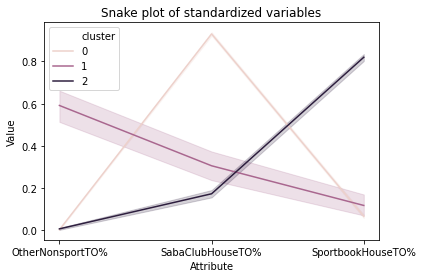

In [21]:
# Calculate average values and size for each cluster
summary = X.groupby(['cluster']).agg({'SabaClubHouseTO%': ['mean'],
                                                    'SportbookHouseTO%': ['mean'],
                                                    'OtherNonsportTO%': ['mean', 'count'],})

print(summary)

# Melt the data into along format so values and metric names are stored in 1 column each
data_melt = pd.melt(X,
                    id_vars=['cluster'],
                    value_vars=['SabaClubHouseTO%', 'SportbookHouseTO%','OtherNonsportTO%'],
                    var_name='Attribute',
                    value_name='Value')# Building the snakeplot

plt.title('Snake plot of standardized variables')
sn.lineplot(x="Attribute", y="Value", hue='cluster', data=data_melt)


In [47]:
X[X['cluster']==0]

,SabaClubHouseTO%,SportbookHouseTO%,OtherNonsportTO%,cluster
0,0.0206,0.7675,0.2117,0
14,0.7978,0.0000,0.2021,0
19,0.9849,0.0035,0.0114,0
33,0.5830,0.0000,0.4169,0
61,0.0461,0.7893,0.1644,0
...,...,...,...,...
1316,0.9854,0.0000,0.0145,0
1331,0.8902,0.0159,0.0937,0
1333,0.5216,0.4597,0.0186,0
1340,0.3198,0.2992,0.3809,0


In [20]:
print(cluster_report(X.iloc[ :, :-1],X['cluster'],min_samples_leaf=10, pruning_level=0.0))

,class_name,instance_count,rule_list
0,0,1164,[1.0] (SabaClubHouseTO% > 0.4063970446586609) and (OtherNonsportTO% <= 0.19006990641355515)
2,1,41,[1.0] (SabaClubHouseTO% <= 0.4063970446586609) and (OtherNonsportTO% > 0.23175369948148727)[0.8823529411764706] (SabaClubHouseTO% > 0.4063970446586609) and (OtherNonsportTO% > 0.19006990641355515)
1,2,174,[1.0] (SabaClubHouseTO% <= 0.4063970446586609) and (OtherNonsportTO% <= 0.23175369948148727)


None


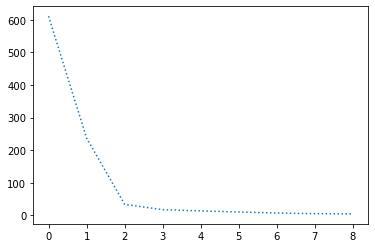

In [49]:

# k-means clustering
from numpy import unique
from numpy import where
from sklearn.datasets import make_classification
from sklearn.cluster import KMeans
from matplotlib import pyplot
from sklearn.preprocessing import MinMaxScaler
# define dataset

#Features=['SabaClubHouseTO%','SportbookHouseTO%','OtherNonsportTO%','Frequency','HouseTOORG', 'SportbookHouseTOORG','OtherNonsportTOORG','SabaClubTOORG','SabaClubAVGStakeORG','SabaClub_ActiveDays']
Features=['SabaClubHouseTO%','SportbookHouseTO%','OtherNonsportTO%']
X = filterData[Features]

#scaler  =  MinMaxScaler()#StandardScaler()
#scaler.fit(X)
#X = pd.DataFrame(scaler.transform(X), columns = X.columns,index=X.index) 

# define the model
model = KMeans(n_clusters=3)
# fit the model
model.fit(X)

model.labels_

# assign a cluster to each example
yhat = model.predict(X)
# retrieve unique clusters
clusters = unique(yhat)
#X['cluster']=yhat
X.insert(3,'cluster',yhat)


#Choosing K with the Elbow Method

sse = []
for K in range(1, 10):
    model = KMeans(n_clusters=K)
    model.fit(X)
    sse.append(model.inertia_) #sum of squared error (SSE)
    
    

plt.plot(sse, linestyle = 'dotted')
plt.show()

#choose K=3




In [50]:
print(cluster_report(X.iloc[ :, :-1],X['cluster'],min_samples_leaf=10, pruning_level=0.0))

,class_name,instance_count,rule_list
1,0,183,[0.8333333333333334] (SabaClubHouseTO% <= 0.7709999978542328) and (SportbookHouseTO% <= 0.593099981546402) and (SabaClubHouseTO% <= 0.12114999815821648)[1.0] (SabaClubHouseTO% <= 0.7709999978542328) and (SportbookHouseTO% <= 0.593099981546402) and (SabaClubHouseTO% > 0.12114999815821648)
0,1,1020,[1.0] (SabaClubHouseTO% > 0.7709999978542328)
2,2,176,[1.0] (SabaClubHouseTO% <= 0.7709999978542328) and (SportbookHouseTO% > 0.593099981546402)


None


        SabaClubHouseTO% SportbookHouseTO% OtherNonsportTO%      
                    mean              mean             mean count
cluster                                                          
0               0.535376          0.333774         0.130734   183
1               0.978131          0.019645         0.002191  1020
2               0.172932          0.816219         0.010743   176


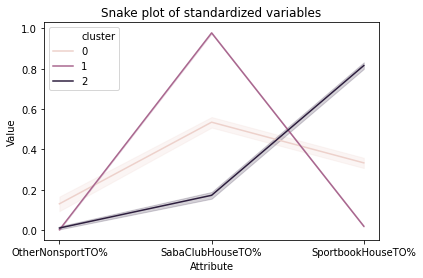

In [51]:
# Calculate average values and size for each cluster
summary = X.groupby(['cluster']).agg({'SabaClubHouseTO%': ['mean'],
                                                    'SportbookHouseTO%': ['mean'],
                                                    'OtherNonsportTO%': ['mean', 'count'],})

print(summary)

# Melt the data into along format so values and metric names are stored in 1 column each
data_melt = pd.melt(X,
                    id_vars=['cluster'],
                    value_vars=['SabaClubHouseTO%', 'SportbookHouseTO%','OtherNonsportTO%'],
                    var_name='Attribute',
                    value_name='Value')# Building the snakeplot

plt.title('Snake plot of standardized variables')
sn.lineplot(x="Attribute", y="Value", hue='cluster', data=data_melt)


In [54]:
X[X['cluster']==1]

,SabaClubHouseTO%,SportbookHouseTO%,OtherNonsportTO%,cluster
3,1.0000,0.0000,0.0000,1
7,0.7745,0.2254,0.0000,1
9,0.9999,0.0000,0.0000,1
10,0.9835,0.0161,0.0003,1
12,0.7941,0.2058,0.0000,1
...,...,...,...,...
1403,1.0000,0.0000,0.0000,1
1405,1.0000,0.0000,0.0000,1
1406,1.0000,0.0000,0.0000,1
1407,1.0000,0.0000,0.0000,1


In [28]:
 
# agglomerative clustering
from numpy import unique
from numpy import where
from sklearn.datasets import make_classification
from sklearn.cluster import AgglomerativeClustering
from matplotlib import pyplot
from sklearn.preprocessing import MinMaxScaler


# define dataset

#Features=['SabaClubHouseTO%','SportbookHouseTO%','OtherNonsportTO%','Frequency','HouseTOORG', 'SportbookHouseTOORG','OtherNonsportTOORG','SabaClubTOORG','SabaClubAVGStakeORG','SabaClub_ActiveDays']
Features=['SabaClubHouseTO%','SportbookHouseTO%','OtherNonsportTO%']
X = filterData[Features]

#scaler  =  MinMaxScaler()#StandardScaler()
#scaler.fit(X)
#X = pd.DataFrame(scaler.transform(X), columns = X.columns,index=X.index) 

# define the model
model = AgglomerativeClustering(n_clusters=3)
# fit model and predict clusters
yhat = model.fit_predict(X)
# retrieve unique clusters
clusters = unique(yhat)
#X['cluster']=yhat
X.insert(3,'cluster',yhat)

In [30]:
print(cluster_report(X.iloc[ :, :-1],X['cluster'],min_samples_leaf=10, pruning_level=0.0))

,class_name,instance_count,rule_list
1,0,251,[1.0] (SabaClubHouseTO% <= 0.8220999836921692) and (SportbookHouseTO% <= 0.7124499976634979) and (SabaClubHouseTO% <= 0.2774000018835068) and (OtherNonsportTO% > 0.7391999959945679)[1.0] (SabaClubHouseTO% <= 0.8220999836921692) and (SportbookHouseTO% <= 0.7124499976634979) and (SabaClubHouseTO% > 0.2774000018835068) and (SabaClubHouseTO% <= 0.8069500029087067)[0.8571428571428571] (SabaClubHouseTO% <= 0.8220999836921692) and (SportbookHouseTO% <= 0.7124499976634979) and (SabaClubHouseTO% > 0.2774000018835068) and (SabaClubHouseTO% > 0.8069500029087067)
0,1,984,[1.0] (SabaClubHouseTO% > 0.8220999836921692) and (OtherNonsportTO% <= 0.061500001698732376)[0.9] (SabaClubHouseTO% > 0.8220999836921692) and (OtherNonsportTO% > 0.061500001698732376)
2,2,144,[0.8] (SabaClubHouseTO% <= 0.8220999836921692) and (SportbookHouseTO% <= 0.7124499976634979) and (SabaClubHouseTO% <= 0.2774000018835068) and (OtherNonsportTO% <= 0.7391999959945679)[1.0] (SabaClubHouseTO% <= 0.8220999836921692) and (SportbookHouseTO% > 0.7124499976634979)


None


        SabaClubHouseTO% SportbookHouseTO% OtherNonsportTO%      
                    mean              mean             mean count
cluster                                                          
0               0.551616          0.353766         0.094506   251
1               0.984684          0.013843         0.001443   984
2               0.129990          0.849699         0.020203   144


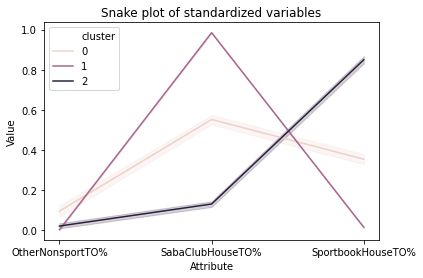

In [31]:
# Calculate average values and size for each cluster
summary = X.groupby(['cluster']).agg({'SabaClubHouseTO%': ['mean'],
                                                    'SportbookHouseTO%': ['mean'],
                                                    'OtherNonsportTO%': ['mean', 'count'],})

print(summary)

# Melt the data into along format so values and metric names are stored in 1 column each
data_melt = pd.melt(X,
                    id_vars=['cluster'],
                    value_vars=['SabaClubHouseTO%', 'SportbookHouseTO%','OtherNonsportTO%'],
                    var_name='Attribute',
                    value_name='Value')# Building the snakeplot

plt.title('Snake plot of standardized variables')
sn.lineplot(x="Attribute", y="Value", hue='cluster', data=data_melt)


In [38]:
# dbscan clustering
from numpy import unique
from numpy import where
from sklearn.datasets import make_classification
from sklearn.cluster import DBSCAN
from matplotlib import pyplot

from sklearn.preprocessing import MinMaxScaler
# define dataset

#Features=['SabaClubHouseTO%','SportbookHouseTO%','OtherNonsportTO%','Frequency','HouseTOORG', 'SportbookHouseTOORG','OtherNonsportTOORG','SabaClubTOORG','SabaClubAVGStakeORG','SabaClub_ActiveDays']
Features=['SabaClubHouseTO%','SportbookHouseTO%','OtherNonsportTO%']
X = filterData[Features]

#scaler  =  MinMaxScaler()#StandardScaler()
#scaler.fit(X)
#X = pd.DataFrame(scaler.transform(X), columns = X.columns,index=X.index) 
# define the model
model = DBSCAN(eps=0.1, min_samples=6)
# fit model and predict clusters
yhat = model.fit_predict(X)
# retrieve unique clusters
clusters = unique(yhat)
#X['cluster']=yhat
X.insert(3,'cluster',yhat)
 

In [39]:
print(cluster_report(X.iloc[ :, :-1],X['cluster'],min_samples_leaf=10, pruning_level=0.0))

,class_name,instance_count,rule_list
1,-1,23,[1.0] (OtherNonsportTO% > 0.12865000218153) and (SportbookHouseTO% > 0.09924999997019768)
0,0,1331,[1.0] (OtherNonsportTO% <= 0.12865000218153)
3,1,11,[0.6111111111111112] (OtherNonsportTO% > 0.12865000218153) and (SportbookHouseTO% <= 0.09924999997019768) and (SabaClubHouseTO% > 0.28575000166893005)
2,2,14,[1.0] (OtherNonsportTO% > 0.12865000218153) and (SportbookHouseTO% <= 0.09924999997019768) and (SabaClubHouseTO% <= 0.28575000166893005)


None


        SabaClubHouseTO% SportbookHouseTO% OtherNonsportTO%      
                    mean              mean             mean count
cluster                                                          
-1              0.272961          0.366165         0.360704    23
 0              0.835345          0.162196         0.002409  1331
 1              0.546318          0.019891         0.433645    11
 2              0.140793          0.017850         0.841243    14


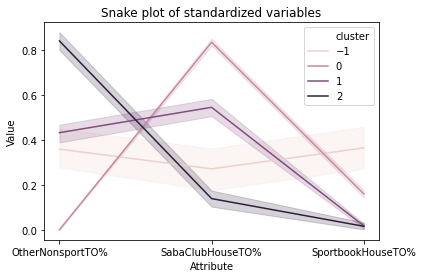

In [40]:
# Calculate average values and size for each cluster
summary = X.groupby(['cluster']).agg({'SabaClubHouseTO%': ['mean'],
                                                    'SportbookHouseTO%': ['mean'],
                                                    'OtherNonsportTO%': ['mean', 'count'],})

print(summary)

# Melt the data into along format so values and metric names are stored in 1 column each
data_melt = pd.melt(X,
                    id_vars=['cluster'],
                    value_vars=['SabaClubHouseTO%', 'SportbookHouseTO%','OtherNonsportTO%'],
                    var_name='Attribute',
                    value_name='Value')# Building the snakeplot

plt.title('Snake plot of standardized variables')
sn.lineplot(x="Attribute", y="Value", hue='cluster', data=data_melt)


In [42]:
# gaussian mixture clustering
from numpy import unique
from numpy import where
from sklearn.datasets import make_classification
from sklearn.mixture import GaussianMixture
from matplotlib import pyplot
from sklearn.preprocessing import MinMaxScaler
# define dataset

#Features=['SabaClubHouseTO%','SportbookHouseTO%','OtherNonsportTO%','Frequency','HouseTOORG', 'SportbookHouseTOORG','OtherNonsportTOORG','SabaClubTOORG','SabaClubAVGStakeORG','SabaClub_ActiveDays']
Features=['SabaClubHouseTO%','SportbookHouseTO%','OtherNonsportTO%']
X = filterData[Features]

#scaler  =  MinMaxScaler()#StandardScaler()
#scaler.fit(X)
#X = pd.DataFrame(scaler.transform(X), columns = X.columns,index=X.index) 

# define the model
model = GaussianMixture(n_components=3, covariance_type='full')
# fit the model
model.fit(X)
# assign a cluster to each example
yhat = model.predict(X)
# retrieve unique clusters
clusters = unique(yhat)
#X['cluster']=yhat
X.insert(3,'cluster',yhat)

In [43]:
print(cluster_report(X.iloc[ :, :-1],X['cluster'],min_samples_leaf=10, pruning_level=0.0))

,class_name,instance_count,rule_list
2,0,119,[1.0] (SabaClubHouseTO% <= 0.9969500005245209) and (OtherNonsportTO% > 0.0035500000230968)
0,1,737,[1.0] (SabaClubHouseTO% > 0.9969500005245209)
1,2,523,[1.0] (SabaClubHouseTO% <= 0.9969500005245209) and (OtherNonsportTO% <= 0.0035500000230968)


None


        SabaClubHouseTO% SportbookHouseTO% OtherNonsportTO%      
                    mean              mean             mean count
cluster                                                          
0               0.528986          0.235487         0.235387   119
1               0.999945          0.000046         0.000005   737
2               0.623699          0.376132         0.000068   523


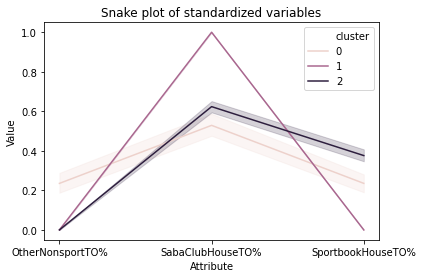

In [44]:
# Calculate average values and size for each cluster
summary = X.groupby(['cluster']).agg({'SabaClubHouseTO%': ['mean'],
                                                    'SportbookHouseTO%': ['mean'],
                                                    'OtherNonsportTO%': ['mean', 'count'],})

print(summary)

# Melt the data into along format so values and metric names are stored in 1 column each
data_melt = pd.melt(X,
                    id_vars=['cluster'],
                    value_vars=['SabaClubHouseTO%', 'SportbookHouseTO%','OtherNonsportTO%'],
                    var_name='Attribute',
                    value_name='Value')# Building the snakeplot

plt.title('Snake plot of standardized variables')
sn.lineplot(x="Attribute", y="Value", hue='cluster', data=data_melt)


In [37]:
X[X['cluster']==4]

,SabaClubHouseTO%,SportbookHouseTO%,OtherNonsportTO%,cluster
19,0.9849,0.0035,0.0114,4
62,0.8984,0.0000,0.1015,4
63,0.5093,0.4804,0.0102,4
72,0.9187,0.0154,0.0657,4
82,0.4154,0.5716,0.0128,4
...,...,...,...,...
1245,0.5139,0.4811,0.0048,4
1316,0.9854,0.0000,0.0145,4
1331,0.8902,0.0159,0.0937,4
1333,0.5216,0.4597,0.0186,4
